In [1]:
import re, warnings, itertools
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); pd.set_option("display.width", 220, "display.max_columns", 60)
STUDY_DIR = Path(r"ablation/study1"); WANDB_ENTITY = None; WANDB_PROJECT = "MILAgeScore_Ablation"; USE_WANDB = True; TOP_K = 15
TL, VL, VM, VMS, VR, EP = "train/loss_corn", "val/loss", "val/mae", "val/mae_s", "val/spearman_rho", "epoch"
OUT = STUDY_DIR / "analysis"; OUT.mkdir(parents=True, exist_ok=True)
FACT = [("bag_size", "Bag size"), ("bpg", "Bags per group"), ("batch", "Batch size")]
def save(fig, name): fig.savefig(OUT / name, dpi=200, bbox_inches="tight"); plt.show()


In [2]:
pat = re.compile(r"bs(\d+)_bpg(\d+)_batch(\d+)")
runs = pd.DataFrame([dict(run=p.name, bag_size=int(m[1]), bpg=int(m[2]), batch=int(m[3]), dir=p, done=(p / ".done").exists()) for p in sorted(STUDY_DIR.iterdir()) if p.is_dir() and (m := pat.fullmatch(p.name))])
print(f"{len(runs)} runs, {runs.done.sum()} done")


60 runs, 60 done


In [3]:
def split_info(r):
    t = (r.dir / "stdout.log").read_text(encoding="utf-8", errors="ignore"); g = lambda p: (re.search(p, t) or [None, np.nan])[1]
    return dict(run=r.run, train_groups=float(g(r"Train groups\s*:\s*(\d+)")), val_groups=float(g(r"Val groups\s*:\s*(\d+)")), val_list=g(r"Val groups\s*:\s*(\[.*\])"))
splits = pd.DataFrame([split_info(r) for r in runs.itertuples()])
print(splits[["train_groups", "val_groups"]].drop_duplicates().to_string(index=False)); print("val groups (run 1):", splits.val_list.iloc[0])


 train_groups  val_groups
         22.0         5.0
val groups (run 1): [(1, 6), (1, 12), (2, 4), (2, 12), (2, 15)]


In [4]:
histories = {}
if USE_WANDB:
    import wandb
    api = wandb.Api(); ent = WANDB_ENTITY or api.default_entity; wb = {}
    for r in api.runs(f"{ent}/{WANDB_PROJECT}"):
        if r.name in set(runs.run) and (r.name not in wb or r.created_at > wb[r.name].created_at): wb[r.name] = r
    histories = {n: r.history(samples=100000, pandas=True) for n, r in wb.items()}
    assert histories, "No matching wandb runs - check entity/project/login."
    first = next(iter(histories.values())); miss = [c for c in (TL, VL, VM, VMS, VR, EP) if c not in first.columns]
    assert not miss, f"Missing wandb columns {miss}. Available: {[c for c in first.columns if not c.startswith('_')]}"
    print(f"matched {len(histories)}/{len(runs)} runs; metrics OK")


wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from C:\Users\goofy\_netrc.


matched 60/60 runs; metrics OK


In [5]:
def epoch_table(h): return h.groupby(EP)[[TL, VL, VM, VMS, VR]].first().dropna(subset=[VM])
def summarise(n, h):
    ep = epoch_table(h); b = ep.loc[ep[VM].idxmin()]
    return dict(run=n, n_epochs=len(ep), best_epoch=ep[VM].idxmin(), train_loss=b[TL], val_loss=b[VL], val_mae=b[VM], val_mae_s=b[VMS], val_rho=b[VR], gap=b[VL] - b[TL])
if histories:
    d = runs.drop(columns="dir").merge(pd.DataFrame([summarise(n, h) for n, h in histories.items()]), on="run").merge(splits.drop(columns="val_list"), on="run")
    d["steps_per_epoch"] = d.train_groups * d.bpg // d.batch; d["steps_to_best"] = d.steps_per_epoch * d.best_epoch; d["cells_per_epoch"] = d.train_groups * d.bpg * d.bag_size
    d["rank_mae"], d["rank_rho"] = d.val_mae.rank(), (-d.val_rho).rank(); d["combined_rank"] = d.rank_mae + d.rank_rho
    d.to_csv(OUT / "run_summary.csv", index=False); print(f"{len(d)} usable runs")


60 usable runs


In [6]:
if histories:
    show = ["run", "train_loss", "val_loss", "val_mae", "val_mae_s", "val_rho", "gap", "best_epoch", "steps_per_epoch"]
    print("== Best by val MAE + Spearman rank =="); print(d.sort_values("combined_rank")[show].head(10).to_string(index=False))
    print("\n== Best by val MAE_s =="); print(d.sort_values("val_mae_s")[show].head(5).to_string(index=False))
    print("\n== Best by val CORN loss (secondary) =="); print(d.sort_values("val_loss")[show].head(5).to_string(index=False))
    print("\nNote: train loss has dropout ON, val has it OFF, so the gap is not a clean overfitting measure.")


== Best by val MAE + Spearman rank ==
                   run  train_loss  val_loss  val_mae  val_mae_s  val_rho      gap  best_epoch  steps_per_epoch
bs100_bpg0100_batch016    0.118580  0.285410 1.126667   0.031234 0.978729 0.166829         2.0            137.0
bs100_bpg0100_batch032    0.120009  0.280680 1.200000   0.048859 0.977749 0.160671         3.0             68.0
bs050_bpg0100_batch128    0.114738  0.274379 0.980000   0.052357 0.974157 0.159642        10.0             17.0
bs100_bpg0500_batch128    0.134815  0.273596 1.240000   0.064238 0.978185 0.138781         2.0             85.0
bs100_bpg0100_batch064    0.117435  0.273348 1.160000   0.059397 0.974265 0.155912         5.0             34.0
bs050_bpg0100_batch064    0.106993  0.287294 1.126667   0.040788 0.970455 0.180301         6.0             34.0
bs100_bpg0250_batch016    0.168520  0.303936 1.386667   0.029479 0.978620 0.135416         1.0            343.0
bs100_bpg0250_batch128    0.116092  0.267593 1.200000   0.056699 0

In [7]:
if histories:
    mets = ["val_mae", "val_mae_s", "val_rho", "val_loss", "train_loss", "gap", "best_epoch", "steps_per_epoch"]
    for f, lab in FACT: t = d.groupby(f)[mets].mean(); print(f"\n--- {lab} (mean over other factors) ---\n{t.round(4)}"); t.to_csv(OUT / f"marginal_{f}.csv")
    X = np.log2(d[["bag_size", "bpg", "batch"]].astype(float)); X = (X - X.mean()) / X.std(); A = np.c_[np.ones(len(X)), X.values]
    for tg in ("val_mae", "val_rho", "val_loss", "gap"): y = d[tg].values; c = np.linalg.lstsq(A, (y - y.mean()) / y.std(), rcond=None)[0]; print(f"{tg:9s} std. coef:", dict(zip(["bag_size", "bpg", "batch"], c[1:].round(3))))
    print("(linear, single seed: indicative only)")



--- Bag size (mean over other factors) ---
          val_mae  val_mae_s  val_rho  val_loss  train_loss     gap  best_epoch  steps_per_epoch
bag_size                                                                                        
25         1.8020     0.0702   0.9422    0.5111      0.1175  0.3936        3.75            495.7
50         1.5877     0.0586   0.9580    0.5218      0.1227  0.3991        5.30            495.7
100        1.5553     0.0592   0.9664    0.5397      0.1116  0.4280        5.00            495.7

--- Bags per group (mean over other factors) ---
      val_mae  val_mae_s  val_rho  val_loss  train_loss     gap  best_epoch  steps_per_epoch
bpg                                                                                         
100    1.3017     0.0505   0.9583    0.2873      0.1224  0.1649      5.3333            64.00
250    1.4250     0.0552   0.9544    0.2925      0.1690  0.1234      2.0833           160.25
500    1.6011     0.0594   0.9634    0.3289      

                 val_mae  val_mae_s  val_rho  val_loss
bag_size           -0.27      -0.26     0.51     -0.20
bpg                 0.77       0.57    -0.13      0.64
batch              -0.29      -0.11    -0.11     -0.61
steps_per_epoch     0.80       0.51    -0.02      0.87
cells_per_epoch     0.57       0.40     0.10      0.48
steps_to_best       0.80       0.39     0.01      0.94
best_epoch          0.09       0.43    -0.36      0.26
val_mae             1.00       0.56    -0.17      0.86
val_mae_s           0.56       1.00    -0.60      0.51
val_rho            -0.17      -0.60     1.00     -0.06
val_loss            0.86       0.51    -0.06      1.00

best_epoch by bpg x batch:
batch   16    32   64    128
bpg                         
100     2.0   3.0  5.3  11.0
250     1.0   1.0  2.3   4.0
500     1.3   1.0  1.0   2.0
1000   13.0  13.3  1.0   1.0
2000    8.7  17.7  1.7   2.3


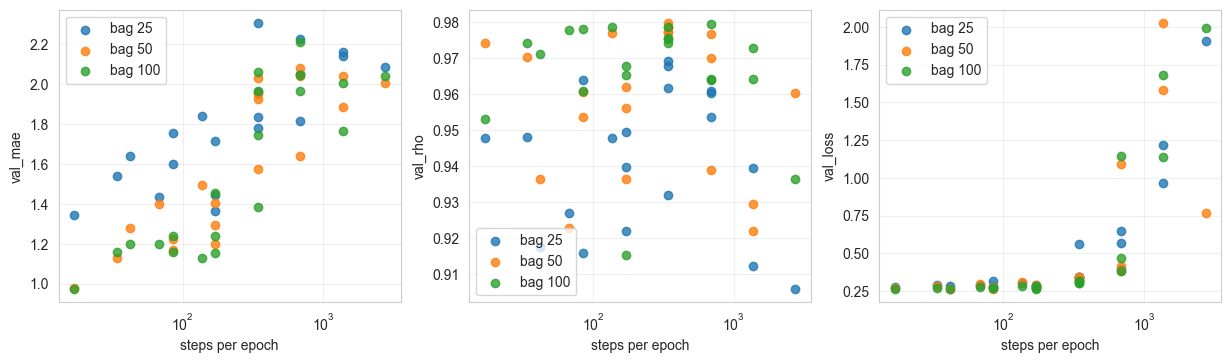

In [8]:
if histories:
    print(d[["bag_size", "bpg", "batch", "steps_per_epoch", "cells_per_epoch", "steps_to_best", "best_epoch", "val_mae", "val_mae_s", "val_rho", "val_loss"]].corr(method="spearman")[["val_mae", "val_mae_s", "val_rho", "val_loss"]].round(2))
    print("\nbest_epoch by bpg x batch:"); print(d.pivot_table(index="bpg", columns="batch", values="best_epoch").round(1))
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for a, m in zip(ax, ("val_mae", "val_rho", "val_loss")):
        for bs, g in d.groupby("bag_size"): a.scatter(g.steps_per_epoch, g[m], label=f"bag {bs}", alpha=.8)
        a.set(xscale="log", xlabel="steps per epoch", ylabel=m); a.grid(alpha=.3); a.legend()
    save(fig, "steps_confound.png")


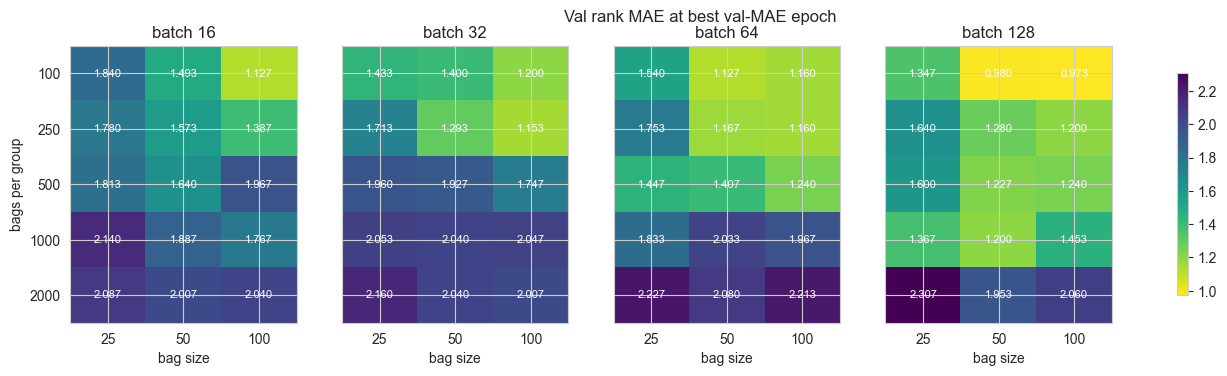

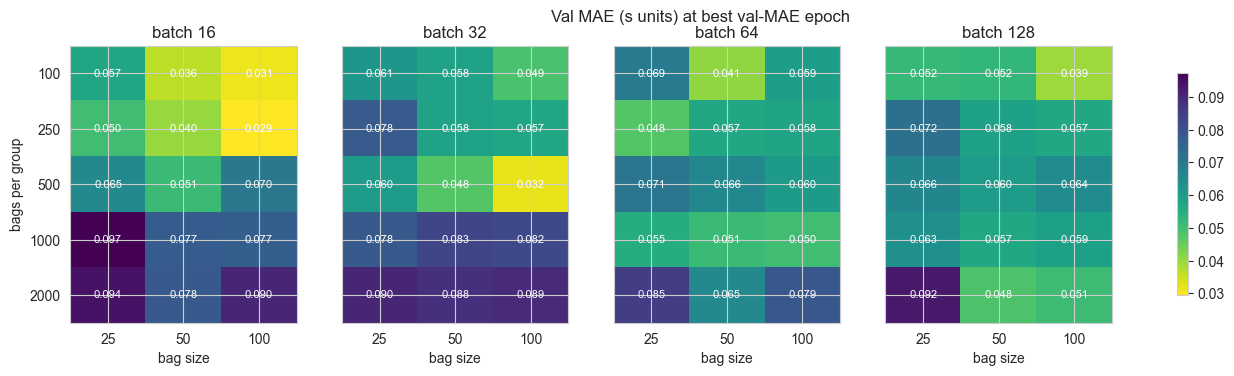

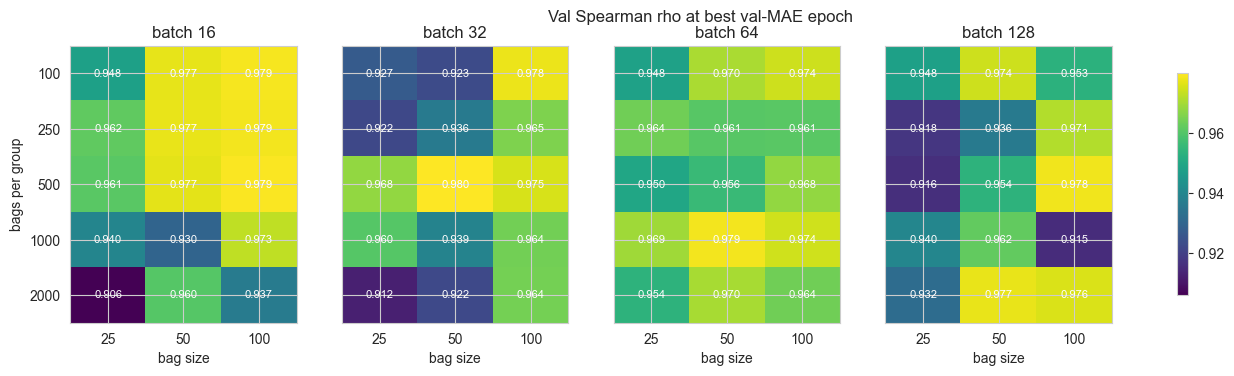

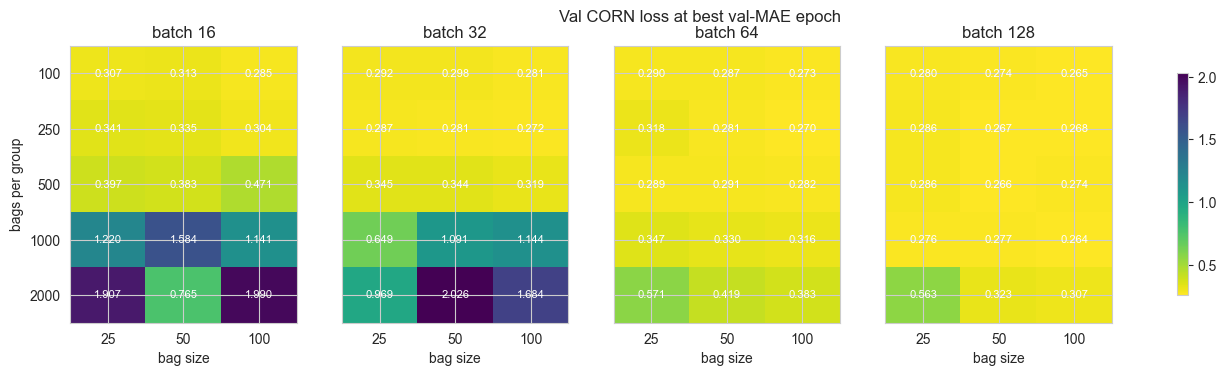

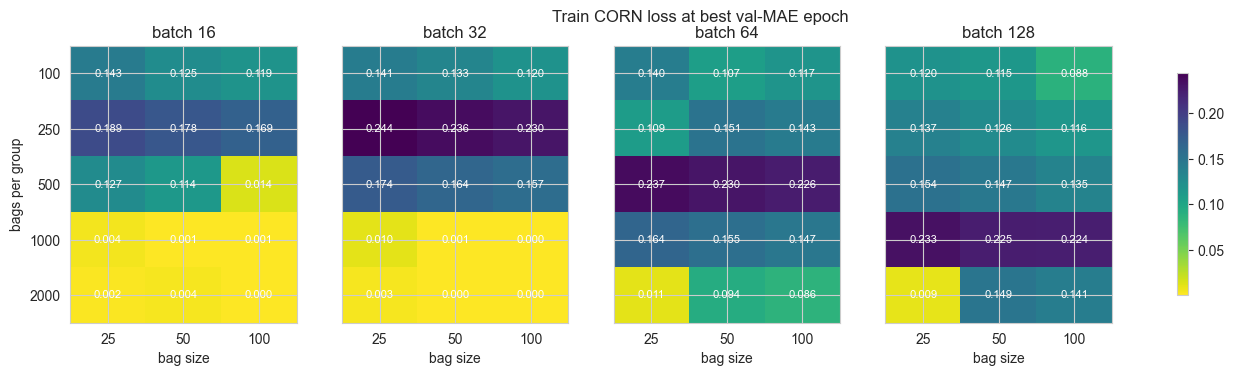

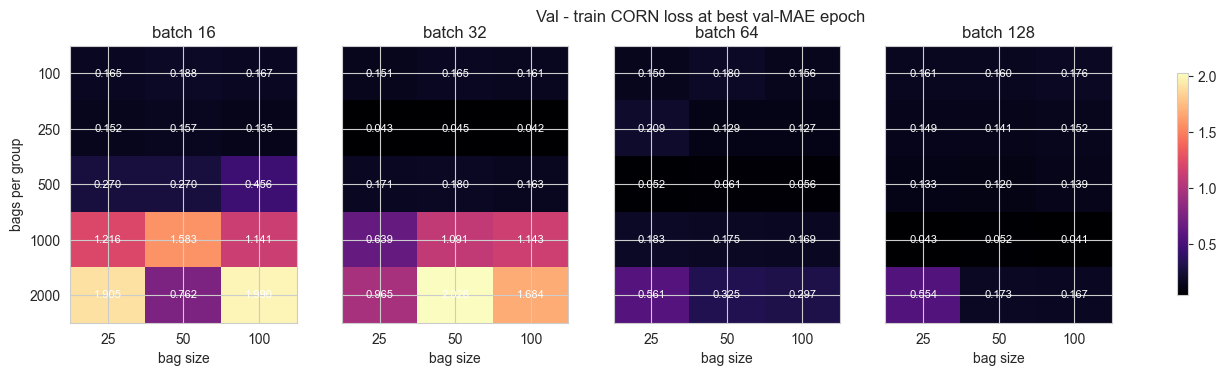

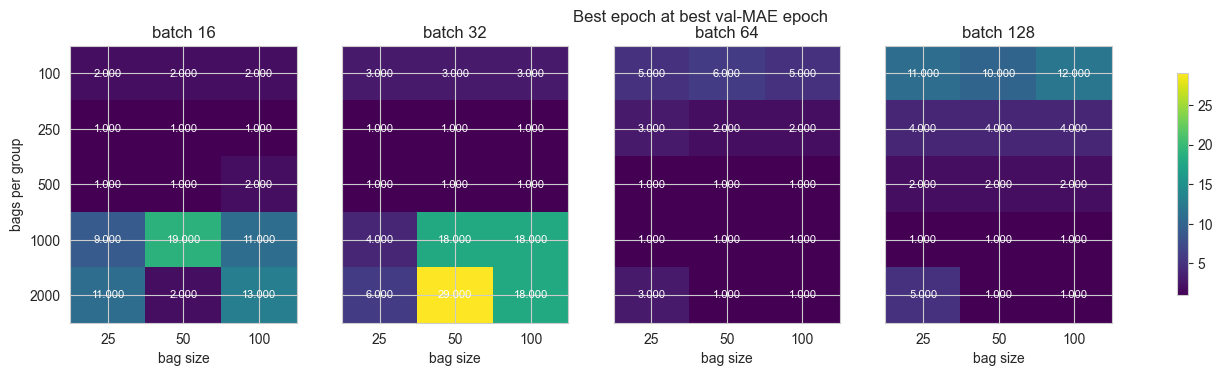

In [9]:
def heat(metric, title, cmap="viridis_r"):
    bs = sorted(d.batch.unique()); fig, axes = plt.subplots(1, len(bs), figsize=(4.2 * len(bs), 3.6), sharey=True); axes = np.atleast_1d(axes)
    for ax, b in zip(axes, bs):
        p = d[d.batch == b].pivot(index="bpg", columns="bag_size", values=metric).sort_index(); im = ax.imshow(p.values, cmap=cmap, vmin=d[metric].min(), vmax=d[metric].max(), aspect="auto")
        ax.set_xticks(range(p.shape[1]), p.columns); ax.set_yticks(range(p.shape[0]), p.index); ax.set_title(f"batch {b}"); ax.set_xlabel("bag size")
        for i, j in itertools.product(range(p.shape[0]), range(p.shape[1])): ax.text(j, i, f"{p.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=8)
    axes[0].set_ylabel("bags per group"); fig.suptitle(title); fig.colorbar(im, ax=list(axes), shrink=.8); save(fig, f"heatmap_{metric}.png")
if histories:
    S = "at best val-MAE epoch"
    for m, t, c in [("val_mae", "Val rank MAE", "viridis_r"), ("val_mae_s", "Val MAE (s units)", "viridis_r"), ("val_rho", "Val Spearman rho", "viridis"), ("val_loss", "Val CORN loss", "viridis_r"), ("train_loss", "Train CORN loss", "viridis_r"), ("gap", "Val - train CORN loss", "magma"), ("best_epoch", "Best epoch", "viridis")]: heat(m, f"{t} {S}", c)


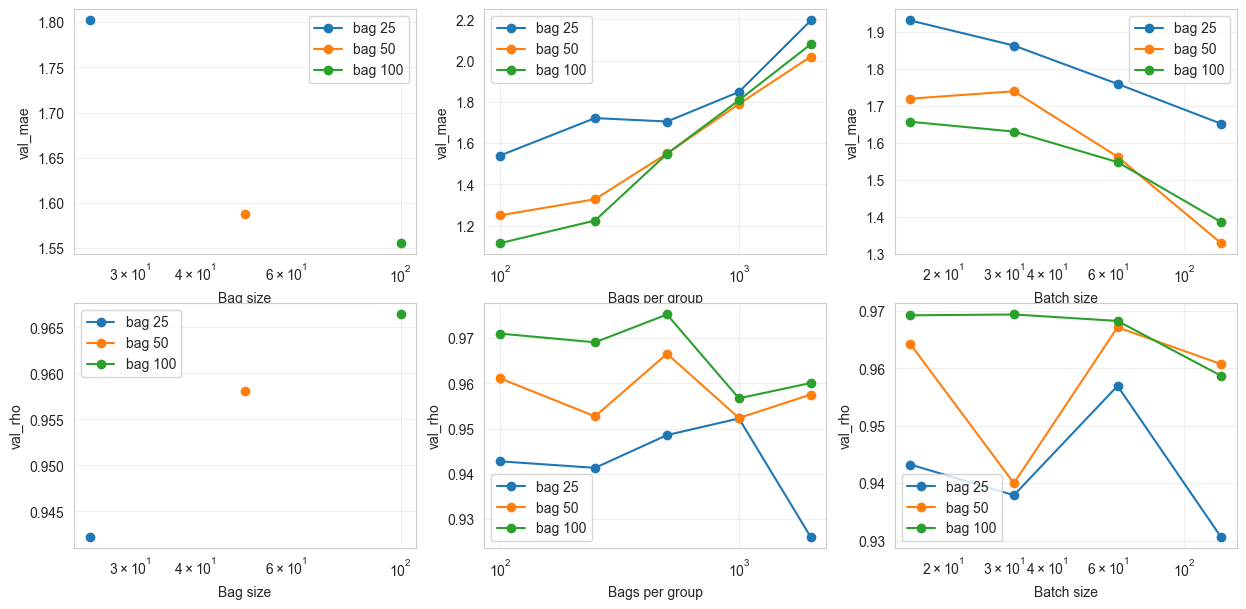

In [10]:
if histories:
    fig, ax = plt.subplots(2, 3, figsize=(15, 7))
    for r_, m in enumerate(("val_mae", "val_rho")):
        for a, (f, lab) in zip(ax[r_], FACT):
            for bs, g in d.groupby("bag_size"): s = g.groupby(f)[m].mean(); a.plot(s.index, s.values, "o-", label=f"bag {bs}")
            a.set(xscale="log", xlabel=lab, ylabel=m); a.grid(alpha=.3); a.legend()
    save(fig, "factor_lines.png")


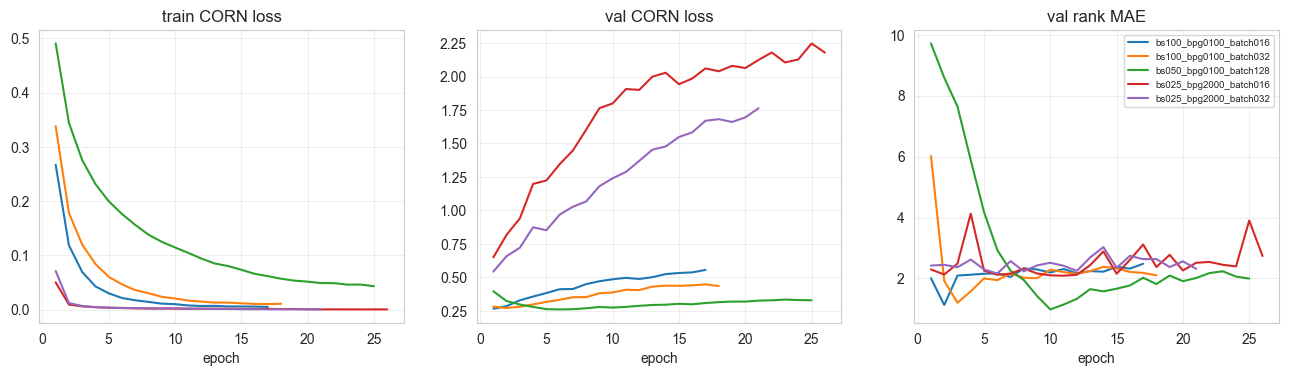

In [11]:
if histories:
    o = d.sort_values("combined_rank").run; fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    for n in list(o.head(3)) + list(o.tail(2)):
        e = epoch_table(histories[n])
        for a, c in zip(ax, (TL, VL, VM)): a.plot(e.index, e[c], label=n)
    for a, t in zip(ax, ("train CORN loss", "val CORN loss", "val rank MAE")): a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3)
    ax[2].legend(fontsize=7); save(fig, "learning_curves.png")


In [12]:
def load_att(r): p = r.dir / "logs" / f"{r.run}_attention.csv"; return pd.read_csv(p) if p.exists() else None
a0 = load_att(next(runs.itertuples())); print(list(a0.columns), len(a0)); print(a0.head())


['well_name', 'treatment', 'passage', 'repeat', 'dose', 'roi', 'label', 'cell_line', 's', 'mean_attention'] 16413
                                well_name treatment  passage  repeat  dose  roi  label  cell_line         s  mean_attention
0  DeHBSS_MSC_Plate_221_P10 - R02-C06.tif   P10_221       10     1.0   0.0    1   10.0          1  0.545455        0.046350
1  DeHBSS_MSC_Plate_221_P10 - R02-C06.tif   P10_221       10     1.0   0.0   10   10.0          1  0.545455        0.037258
2  DeHBSS_MSC_Plate_221_P10 - R02-C06.tif   P10_221       10     1.0   0.0   12   10.0          1  0.545455        0.046837
3  DeHBSS_MSC_Plate_221_P10 - R02-C06.tif   P10_221       10     1.0   0.0   14   10.0          1  0.545455        0.050444
4  DeHBSS_MSC_Plate_221_P10 - R02-C06.tif   P10_221       10     1.0   0.0   16   10.0          1  0.545455        0.035527


In [13]:
ATT_W, ATT_BAG = None, None
nc = a0.select_dtypes("number").columns.tolist()
ATT_W = ATT_W or next((c for c in nc if re.search(r"attn|attention|weight|alpha", c, re.I)), None); ATT_BAG = ATT_BAG or next((c for c in a0.columns if re.search(r"bag|sample|draw", c, re.I)), None)
print("weight col:", ATT_W, "| bag col:", ATT_BAG); assert ATT_W, "Set ATT_W to the attention-weight column."
def bag_stats(w):
    w = np.asarray(w, float); w = w / w.sum(); h = -(w * np.log(w + 1e-12)).sum(); k = max(1, int(np.ceil(.1 * len(w))))
    return h / np.log(len(w)), w.max() * len(w), np.sort(w)[-k:].sum(), np.exp(h) / len(w)
def att_metrics(r):
    a = load_att(r)
    if a is None: return None
    n = r.bag_size; w = a[ATT_W].astype(float).values
    if ATT_BAG and ATT_BAG in a and a.groupby(ATT_BAG).size().median() == n: gs, mode = [g[ATT_W].values for _, g in a.groupby(ATT_BAG)], "per-bag"
    elif not ATT_BAG and len(a) % n == 0: gs, mode = list(w.reshape(-1, n)), "per-bag(blocks)"
    else: gs, mode = [w], "per-cell"
    s = np.array([bag_stats(g) for g in gs]).mean(0); return dict(run=r.run, mode=mode, n_bags=len(gs), norm_entropy=s[0], max_w_x_uniform=s[1], top10pct_mass=s[2], eff_cell_fraction=s[3])
att = runs.drop(columns="dir").merge(pd.DataFrame([m for m in map(att_metrics, runs.itertuples()) if m]), on="run")
if histories: att = att.merge(d[["run", "val_mae", "val_rho", "val_loss"]], on="run", how="left")
att.to_csv(OUT / "attention_metrics.csv", index=False); print(att["mode"].value_counts().to_dict()); print(att.sort_values("norm_entropy").head(8).to_string(index=False))


weight col: mean_attention | bag col: None
{'per-cell': 60}
                   run  bag_size  bpg  batch  done     mode  n_bags  norm_entropy  max_w_x_uniform  top10pct_mass  eff_cell_fraction  val_mae  val_rho  val_loss
bs100_bpg2000_batch032       100 2000     32  True per-cell       1      0.994050         3.579221       0.174228           0.943888 2.006667 0.964250  1.684180
bs100_bpg1000_batch032       100 1000     32  True per-cell       1      0.994787         3.163566       0.167962           0.950663 2.046667 0.964197  1.143737
bs100_bpg2000_batch016       100 2000     16  True per-cell       1      0.994948         3.028610       0.166469           0.952151 2.040000 0.936587  1.990077
bs025_bpg2000_batch128        25 2000    128  True per-cell       1      0.994981         2.797273       0.164315           0.952453 2.306667 0.932024  0.562961
bs050_bpg1000_batch032        50 1000     32  True per-cell       1      0.995511         2.551436       0.159052           0.957362 2.


--- bag_size ---
          norm_entropy  max_w_x_uniform  top10pct_mass  eff_cell_fraction
bag_size                                                                 
25               0.998            1.892          0.138              0.979
50               0.998            1.954          0.139              0.979
100              0.997            2.176          0.144              0.975

--- bpg ---
      norm_entropy  max_w_x_uniform  top10pct_mass  eff_cell_fraction
bpg                                                                  
100          0.998            1.830          0.136              0.982
250          0.998            1.801          0.135              0.984
500          0.998            1.842          0.135              0.983
1000         0.997            2.129          0.144              0.974
2000         0.996            2.434          0.152              0.966

--- batch ---
       norm_entropy  max_w_x_uniform  top10pct_mass  eff_cell_fraction
batch                  

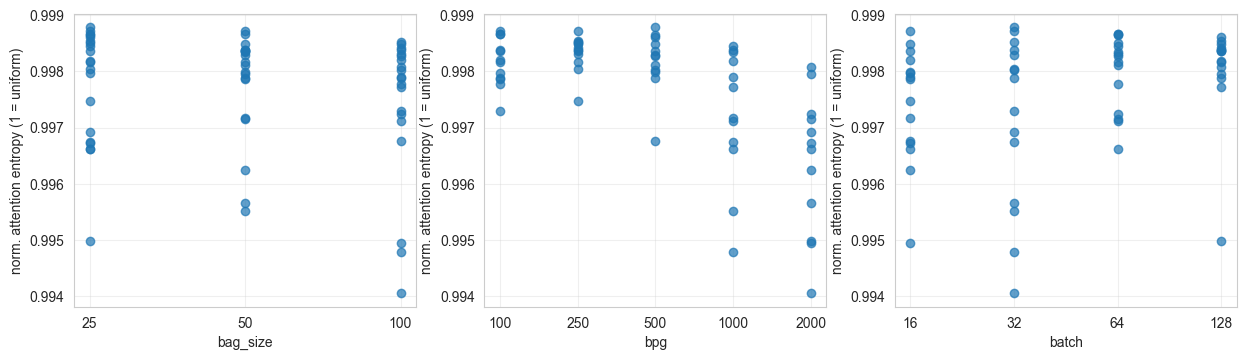

In [14]:
AM = ["norm_entropy", "max_w_x_uniform", "top10pct_mass", "eff_cell_fraction"]
for f, _ in FACT: print(f"\n--- {f} ---\n{att.groupby(f)[AM].mean().round(3)}")
if histories: print("\nSpearman vs outcomes:\n", att[AM + ["val_mae", "val_rho", "val_loss"]].corr(method="spearman")[["val_mae", "val_rho", "val_loss"]].round(2))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (f, _) in zip(ax, FACT): a.scatter(att[f].astype(str), att.norm_entropy, alpha=.7); a.set(xlabel=f, ylabel="norm. attention entropy (1 = uniform)"); a.grid(alpha=.3)
save(fig, "attention_entropy.png")


In [15]:
def load_imp(r):
    for s in ("importance_normalised", "importance"):
        p = r.dir / "logs" / f"{r.run}_{s}.csv"
        if p.exists(): return pd.read_csv(p)
i0 = load_imp(next(runs.itertuples())); print(list(i0.columns)); print(i0.head())


['feature', 'feature_type', 'global_mean_abs_ig']
    feature feature_type  global_mean_abs_ig
0    ratio5       manual            1.094263
1  latent_4       latent            1.040976
2   kurt_10       manual            0.931570
3    ratio6       manual            0.919124
4  latent_7       latent            0.915921


In [16]:
FEAT, VALC = None, None
FEAT = FEAT or next((c for c in i0.columns if i0[c].dtype == object), i0.columns[0]); num_ = i0.select_dtypes("number").columns.tolist()
VALC = VALC or next((c for c in num_ if re.search(r"import|attr|ig|norm", c, re.I)), num_[0]); print("feature col:", FEAT, "| value col:", VALC)
def share(t): s = t.set_index(FEAT)[VALC].abs(); return s / s.sum()
M = pd.DataFrame({r.run: share(t) for r in runs.itertuples() if (t := load_imp(r)) is not None}).fillna(0); rank = M.rank(ascending=False)
cons = pd.DataFrame({"mean_share": M.mean(axis=1), "sd_share": M.std(axis=1), "cv": M.std(axis=1) / M.mean(axis=1), "mean_rank": rank.mean(axis=1), "rank_sd": rank.std(axis=1), "in_top_k_frac": (rank <= TOP_K).mean(axis=1)}).sort_values("mean_rank")
cons.to_csv(OUT / "feature_consensus.csv"); print(M.shape); print(cons.head(25).round(4))


feature col: feature | value col: global_mean_abs_ig
(52, 60)
                mean_share  sd_share      cv  mean_rank  rank_sd  in_top_k_frac
feature                                                                        
ratio5              0.0552    0.0143  0.2585     1.3833   0.6911         1.0000
latent_4            0.0369    0.0089  0.2404     5.6667   6.2455         0.9167
var_20per_12        0.0338    0.0079  0.2330     6.9500   5.1369         0.9167
mean_13             0.0302    0.0050  0.1657     8.8000   4.1407         0.9167
skew_40per_3        0.0326    0.0109  0.3349     9.0167   5.3186         0.9000
num_neighbours      0.0296    0.0050  0.1696     9.4500   5.1038         0.9000
mean_12             0.0307    0.0099  0.3210    10.1500   8.1840         0.7500
latent_15           0.0282    0.0063  0.2239    11.2000   6.7493         0.8333
ratio4              0.0278    0.0077  0.2764    11.9833   6.1575         0.7667
rawIntDen_12        0.0263    0.0046  0.1764    12.3000   

In [17]:
sp = M.corr(method="spearman"); top = {c: set(rank[c].nsmallest(TOP_K).index) for c in M}; iu = np.triu_indices(len(M.columns), 1)
jac = np.array([[len(top[a] & top[b]) / len(top[a] | top[b]) for b in M] for a in M])
print(f"Pairwise Spearman: mean {sp.values[iu].mean():.3f}, min {sp.values[iu].min():.3f} | top-{TOP_K} Jaccard: mean {jac[iu].mean():.3f}, min {jac[iu].min():.3f}")
print(f"In the top-{TOP_K} of EVERY run: {list(cons.index[cons.in_top_k_frac == 1])}")
meta = runs.drop(columns="dir").set_index("run").loc[M.columns].copy(); meta["corr_to_consensus"] = [M[c].corr(M.mean(axis=1), method="spearman") for c in M]
if histories: meta = meta.join(d.set_index("run")[["val_mae", "val_rho"]])
for f, _ in FACT: print(f"\nAgreement with consensus by {f}:\n{meta.groupby(f).corr_to_consensus.mean().round(3).to_string()}")
if histories: print("\nSpearman(agreement, outcome):", meta[["corr_to_consensus", "val_mae", "val_rho"]].corr(method="spearman").iloc[0, 1:].round(3).to_dict())


Pairwise Spearman: mean 0.675, min 0.301 | top-15 Jaccard: mean 0.540, min 0.111
In the top-15 of EVERY run: ['ratio5']

Agreement with consensus by bag_size:
bag_size
25     0.826
50     0.844
100    0.781

Agreement with consensus by bpg:
bpg
100     0.818
250     0.840
500     0.839
1000    0.807
2000    0.780

Agreement with consensus by batch:
batch
16     0.800
32     0.800
64     0.834
128    0.833

Spearman(agreement, outcome): {'val_mae': -0.215, 'val_rho': 0.185}


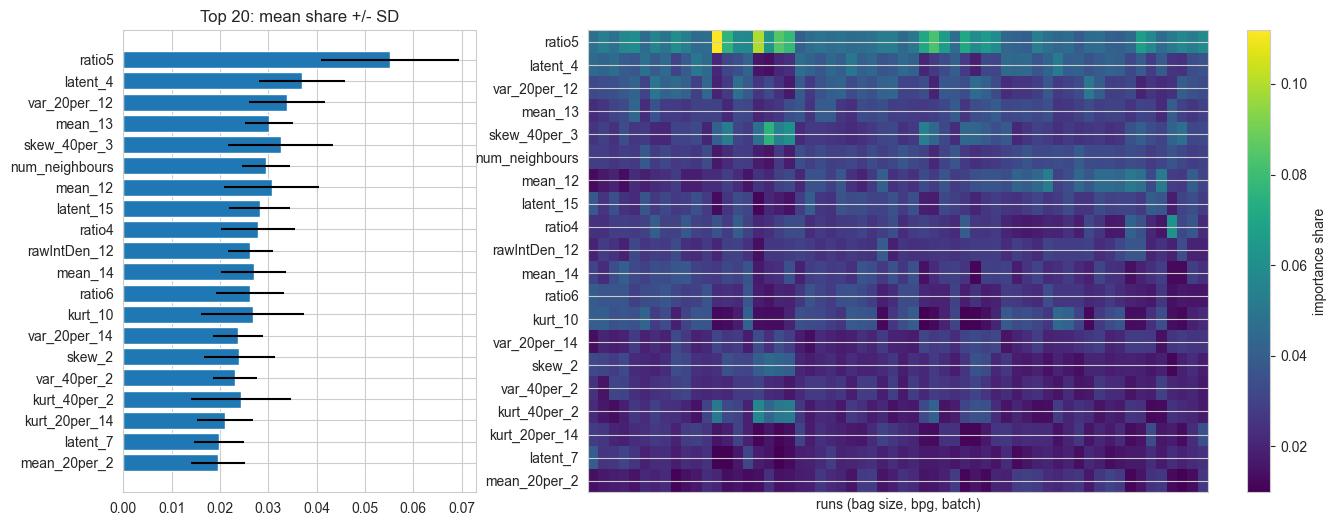

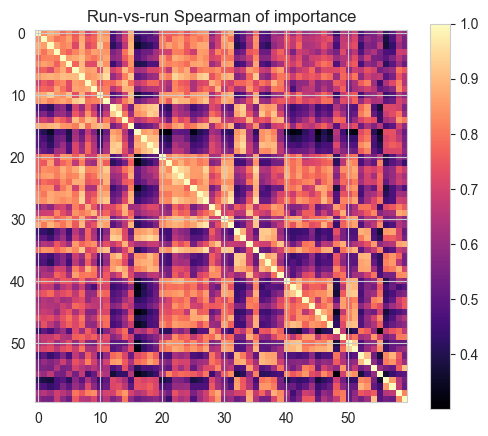

saved to ablation\study1\analysis


In [19]:
tf = list(cons.index[:20]); order = [o for o in runs.sort_values(["bag_size", "bpg", "batch"]).run if o in M.columns]
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw=dict(width_ratios=[1, 2.2]))
ax[0].barh(tf[::-1], cons.loc[tf, "mean_share"].values[::-1], xerr=cons.loc[tf, "sd_share"].values[::-1]); ax[0].set_title("Top 20: mean share +/- SD")
im = ax[1].imshow(M.loc[tf, order].values, aspect="auto", cmap="viridis"); ax[1].set_yticks(range(len(tf)), tf); ax[1].set_xticks([]); ax[1].set_xlabel("runs (bag size, bpg, batch)"); fig.colorbar(im, ax=ax[1], label="importance share"); save(fig, "feature_importance_consistency.png")
fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(sp.loc[order, order].values, vmin=sp.values.min(), vmax=1, cmap="magma"); ax.set_title("Run-vs-run Spearman of importance"); fig.colorbar(im); save(fig, "run_similarity.png")
print("saved to", OUT)
